# Лабораторна робота №3. Прогин балок і пластин

In [1]:
import numpy as np
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve
import matplotlib.pyplot as plt

### Постановка задачі

$$
EJ\,y^{IV}(x) = w(x), \quad x \in [a, b]
$$

На кожному кінці задаються дві умови з набору $y,\ y',\ y'',\ y'''$ (прогин, кут нахилу, момент, поперечна сила).
Далі $EJ = 1$, тобто $y^{IV} = f(x)$.

### П'ятидіагональна прогонка

$$
a_i y_{i-2} + b_i y_{i-1} + c_i y_i + d_i y_{i+1} + e_i y_{i+2} = f_i, \qquad y_i = K_i y_{i+1} + L_i y_{i+2} + M_i
$$

In [2]:
def progonka5(a, b, c, d, e, f):
    n = len(c)
    K = np.zeros(n + 2)
    L = np.zeros(n + 2)
    M = np.zeros(n + 2)
    for i in range(n):
        beta = a[i] * K[i - 2] + b[i]
        den = c[i] + beta * K[i - 1] + a[i] * L[i - 2]
        K[i] = -(d[i] + beta * L[i - 1]) / den
        L[i] = -e[i] / den
        M[i] = (f[i] - beta * M[i - 1] - a[i] * M[i - 2]) / den

    y = np.zeros(n)
    y[n - 1] = M[n - 1]
    y[n - 2] = K[n - 2] * y[n - 1] + M[n - 2]
    for i in range(n - 3, -1, -1):
        y[i] = K[i] * y[i + 1] + L[i] * y[i + 2] + M[i]
    return y

### Різницева схема і граничні умови

$$
y^{IV}_i \approx \frac{y_{i+2} - 4y_{i+1} + 6y_i - 4y_{i-1} + y_{i-2}}{h^4}, \quad i = 2, \dots, n-2
$$

Рядки $0, 1$ і $n-1, n$ системи займають граничні умови (односторонні різниці, як у методичці):

$$
y' \approx \frac{y_1 - y_0}{h}, \quad y'' \approx \frac{y_2 - 2y_1 + y_0}{h^2}, \quad y''' \approx \frac{y_3 - 3y_2 + 3y_1 - y_0}{h^3}
$$

Внутрішня опора $y(x_p) = v$ — рядок $i_p$ замінюється на $y_{i_p} = v$.

In [3]:
DIFF = {0: [1], 1: [-1, 1], 2: [1, -2, 1], 3: [-1, 3, -3, 1]}


def set_bc(A, F, h, n, left, right):
    def put(row, start, k, val):
        A[:, row] = 0
        for s, cf in enumerate(DIFF[k]):
            A[start + s - row + 2, row] = cf / h**k
        F[row] = val

    (k1, v1), (k2, v2) = sorted(left)
    put(0, 0, k1, v1)
    put(1, 0, k2, v2)
    (k1, v1), (k2, v2) = sorted(right)
    put(n, n - k1, k1, v1)
    put(n - 1, n - k2, k2, v2)


def beam(f, left, right, n=1200, xa=0, xb=1, points=()):
    h = (xb - xa) / n
    x = np.linspace(xa, xb, n + 1)
    A = np.zeros((5, n + 1))
    F = np.zeros(n + 1)
    A[:, 2:n - 1] = np.array([1, -4, 6, -4, 1])[:, None] / h**4
    F[2:n - 1] = f(x[2:n - 1])
    set_bc(A, F, h, n, left, right)
    for xp, v in points:
        i = round((xp - xa) / h)
        A[:, i] = 0
        A[2, i] = 1
        F[i] = v
    return x, progonka5(*A, F)


def show1d(x, y, ye=None, title="", points=()):
    plt.figure(figsize=(9, 5))
    plt.plot(x, y, "--", lw=2, label="numerical")
    if ye is not None:
        plt.plot(x, ye(x), lw=1, label="analytical")
    for xp, v in points:
        plt.plot(xp, v, "r*", ms=10)
    plt.xlabel("x")
    plt.ylabel("y(x)")
    plt.title(title)
    plt.grid()
    plt.legend()
    plt.show()

### 1. Одновимірна балка

#### Задача 2.3. Жорстко закріплені кінці

$$
y^{IV} = 10^4 \sin 10x, \quad y(0) = 1,\ y'(0) = 0, \quad y(1) = 1,\ y'(1) = 0
$$

$$
y = \sin 10x - 10x + \frac{x^2(20\cos 10 - 6\sin 10 + 40)}{2} - \frac{x^3(60\cos 10 - 12\sin 10 + 60)}{6} + 1
$$

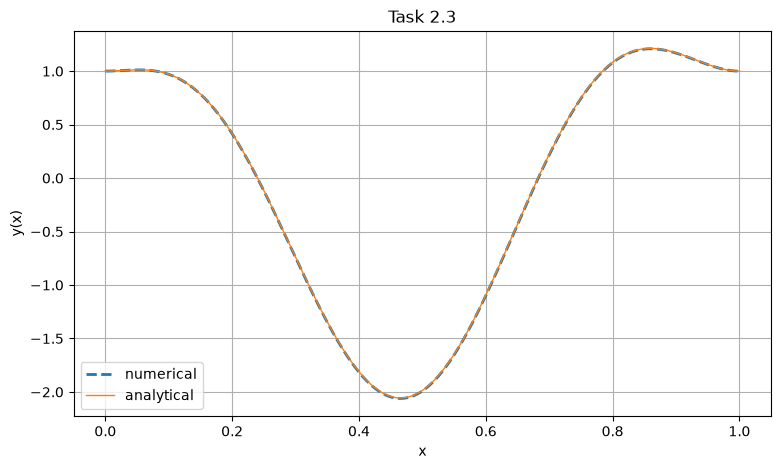

In [4]:
y23 = lambda x: (np.sin(10 * x) - 10 * x + x**2 * (20 * np.cos(10) - 6 * np.sin(10) + 40) / 2
                 - x**3 * (60 * np.cos(10) - 12 * np.sin(10) + 60) / 6 + 1)

x, y = beam(lambda x: 1e4 * np.sin(10 * x), [(0, 1), (1, 0)], [(0, 1), (1, 0)])
show1d(x, y, y23, "Task 2.3")

#### Задача 2.4. Точкове відхилення

$$
y^{IV} = 0, \quad y(0) = y'(0) = 0, \quad y(1) = y'(1) = 0, \quad y(1/3) = -1
$$

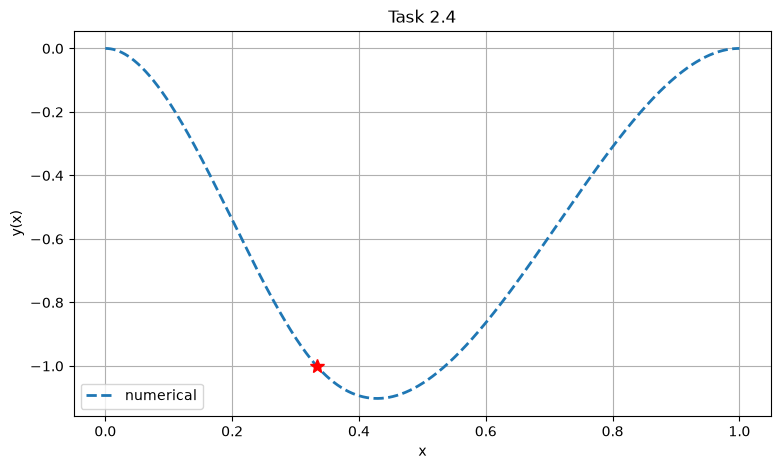

In [5]:
x, y = beam(lambda x: 0 * x, [(0, 0), (1, 0)], [(0, 0), (1, 0)], points=[(1 / 3, -1)])
show1d(x, y, title="Task 2.4", points=[(1 / 3, -1)])

#### Задача 2.5. Правий кінець рухається по вертикалі

$$
y^{IV} = -100(1 - x)^2, \quad y(0) = y'(0) = 0, \quad y'(1) = y''(1) = 0
$$

$$
y = -\frac{5x^6}{18} + \frac{5x^5}{3} - \frac{25x^4}{6} + 5x^3 - \frac{5x^2}{2}
$$

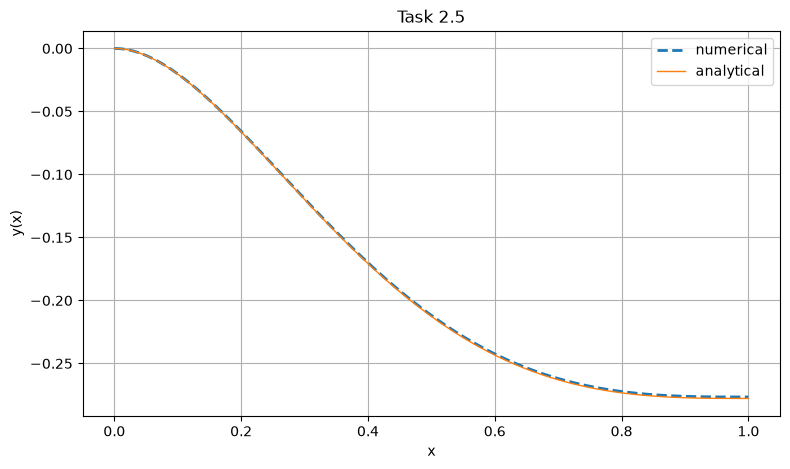

In [6]:
y25 = lambda x: -5 * x**6 / 18 + 5 * x**5 / 3 - 25 * x**4 / 6 + 5 * x**3 - 5 * x**2 / 2

x, y = beam(lambda x: -100 * (1 - x)**2, [(0, 0), (1, 0)], [(1, 0), (2, 0)])
show1d(x, y, y25, "Task 2.5")

#### Задача 2.6. Три прольоти, закріплені кінці

$$
y^{IV} = -10^4 x, \quad y(0) = y(1/3) = y(2/3) = y(1) = 0, \quad y'(0) = y'(1) = 0
$$

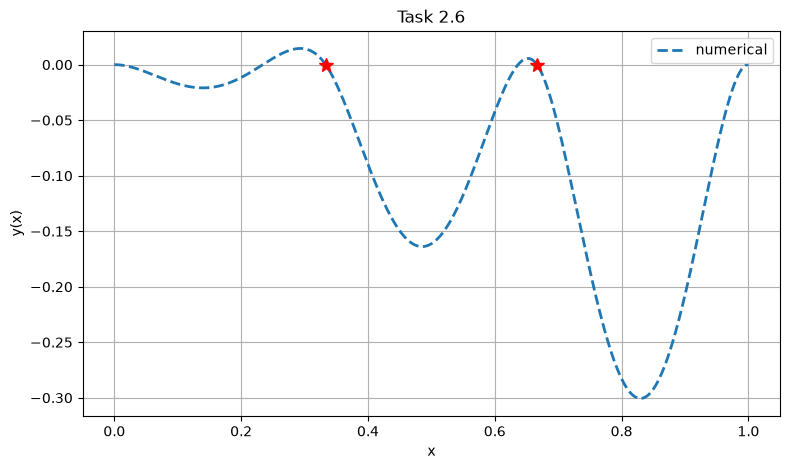

In [7]:
sup = [(1 / 3, 0), (2 / 3, 0)]
x, y = beam(lambda x: -1e4 * x, [(0, 0), (1, 0)], [(0, 0), (1, 0)], points=sup)
show1d(x, y, title="Task 2.6", points=sup)

#### Задача 2.7. Три прольоти, рухомі крайні опори

$$
y^{IV} = -10^4 x(1 - x), \quad y'(0) = y(1/3) = y(2/3) = y'(1) = 0, \quad y''(0) = y''(1) = 0
$$

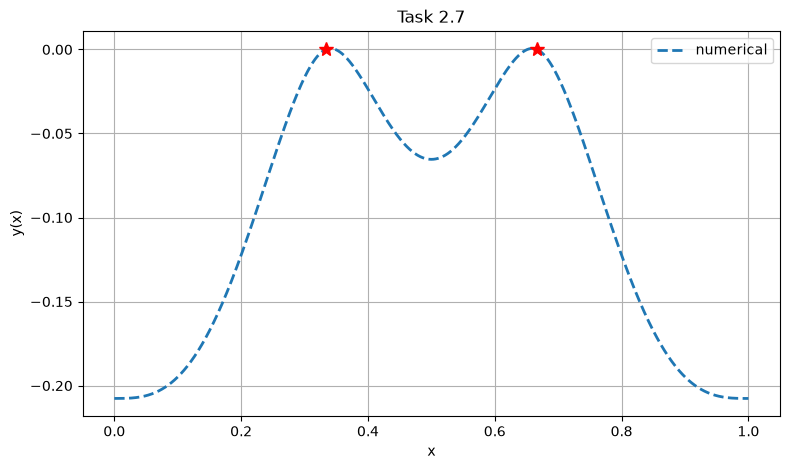

In [8]:
x, y = beam(lambda x: -1e4 * x * (1 - x), [(1, 0), (2, 0)], [(1, 0), (2, 0)], points=sup)
show1d(x, y, title="Task 2.7", points=sup)

#### Задача 2.8. Консоль (лівий кінець закріплений, правий вільний)

$$
y^{IV} = -x(1 - x), \quad y(0) = y'(0) = 0, \quad y''(1) = y'''(1) = 0
$$

$$
y = \frac{0.025x^6}{9} - \frac{0.025x^5}{3} + \frac{0.25x^3}{9} - \frac{0.125x^2}{3}
$$

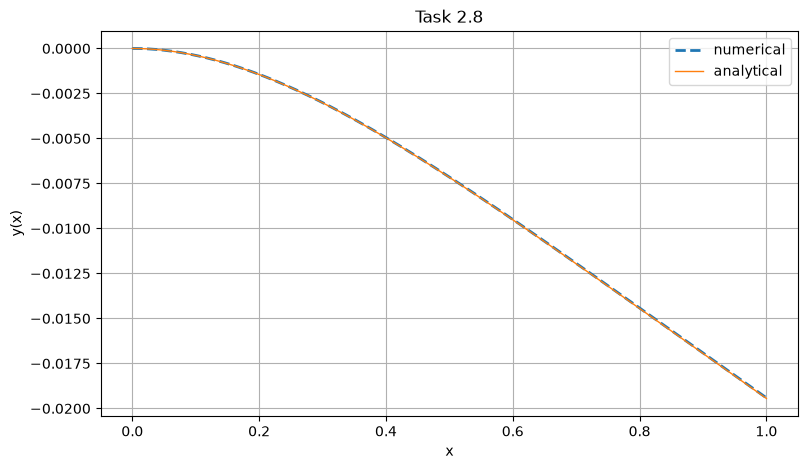

In [9]:
y28 = lambda x: 0.025 * x**6 / 9 - 0.025 * x**5 / 3 + 0.25 * x**3 / 9 - 0.125 * x**2 / 3

x, y = beam(lambda x: -x * (1 - x), [(0, 0), (1, 0)], [(2, 0), (3, 0)])
show1d(x, y, y28, "Task 2.8")

### 2. Двовимірна пластина

$$
\frac{\partial^4 U}{\partial x^4} + 2\frac{\partial^4 U}{\partial x^2 \partial y^2} + \frac{\partial^4 U}{\partial y^4} = f(x, y), \quad (x, y) \in [0, 1]^2
$$

При $h_x = h_y = h$ 13-точкова схема:

$$
\frac{1}{h^4}\Big(20U_{i,j} - 8\sum_{\text{4 сусіди}} U + 2\sum_{\text{4 діагональні}} U + \sum_{\text{4 через один}} U\Big) = f_{i,j}
$$

In [10]:
STENCIL = [(0, 0, 20),
           (-1, 0, -8), (1, 0, -8), (0, -1, -8), (0, 1, -8),
           (-1, -1, 2), (-1, 1, 2), (1, -1, 2), (1, 1, 2),
           (-2, 0, 1), (2, 0, 1), (0, -2, 1), (0, 2, 1)]


def plate(f, n=60, points=()):
    h = 1 / n
    x = np.linspace(0, 1, n + 1)

    def num(i, j):
        return i * (n + 1) + j

    fixed = {(round(xp / h), round(yp / h)): v for xp, yp, v in points}
    N = (n + 1)**2
    M = lil_matrix((N, N))
    rhs = np.zeros(N)

    for i in range(n + 1):
        for j in range(n + 1):
            k = num(i, j)
            M[k, k] = 1
            if i in (0, 1, n - 1, n) or j in (0, 1, n - 1, n):
                pass
            elif (i, j) in fixed:
                rhs[k] = fixed[(i, j)]
            else:
                for di, dj, c in STENCIL:
                    M[k, num(i + di, j + dj)] = c / h**4
                rhs[k] = f(x[i], x[j])

    U = spsolve(M.tocsr(), rhs).reshape((n + 1, n + 1))
    return x, U


def surface(x, y, U, title, zlabel="U(x, y)", marks=()):
    X, Y = np.meshgrid(x, y, indexing="ij")
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection="3d")
    ax.plot_surface(X, Y, U, cmap="jet", edgecolor="k", lw=0.1)
    for xp, yp, v in marks:
        ax.scatter(xp, yp, v, c="k", s=30)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel(zlabel)
    ax.set_title(title)
    plt.show()

Граничні умови займають два крайні ряди вузлів: $U_0 = 0$ і $U_1 = U_0 + h\,U_n = 0$ (защемлення).

#### Задача 3.1. Дві прольоти, опора по лінії $x = 1/2$

$$
\Delta^2 U = -100, \quad U = U_n = 0 \text{ на межі}, \quad U(1/2, y) = 0
$$

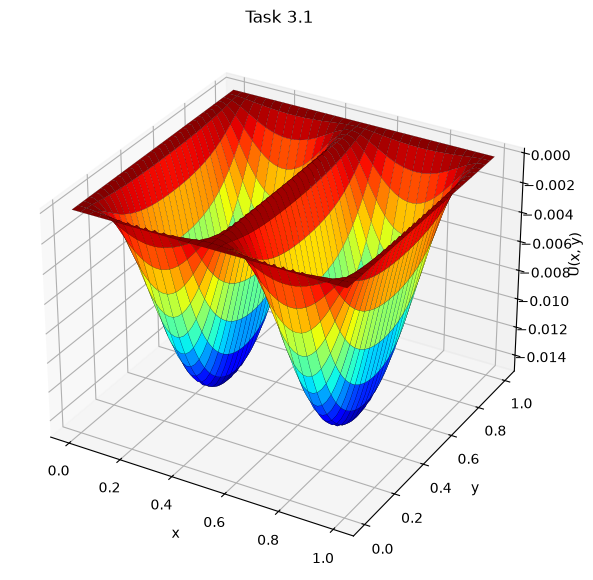

min U = -0.014829750256193078


In [11]:
n = 60
line = [(0.5, y, 0) for y in np.linspace(0, 1, n + 1)]
x, U = plate(lambda x, y: -100, n, points=line)
surface(x, x, U, "Task 3.1")
print("min U =", U.min())

#### Задача 3.2. Точкова опора в центрі

$$
\Delta^2 U = -100, \quad U = U_n = 0 \text{ на межі}, \quad U(1/2, 1/2) = 0
$$

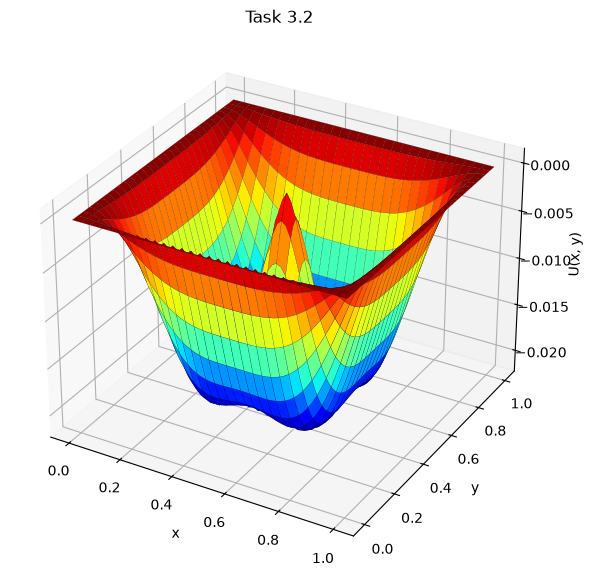

min U = -0.02077301904490326


In [12]:
x, U = plate(lambda x, y: -100, n, points=[(0.5, 0.5, 0)])
surface(x, x, U, "Task 3.2", marks=[(0.5, 0.5, 0)])
print("min U =", U.min())

#### Задача 3.3. Задані відхилення у чотирьох точках

$$
\Delta^2 U = 0, \quad U\left(\tfrac13, \tfrac13\right) = U\left(\tfrac13, \tfrac23\right) = U\left(\tfrac23, \tfrac23\right) = -1, \quad U\left(\tfrac23, \tfrac13\right) = 2
$$

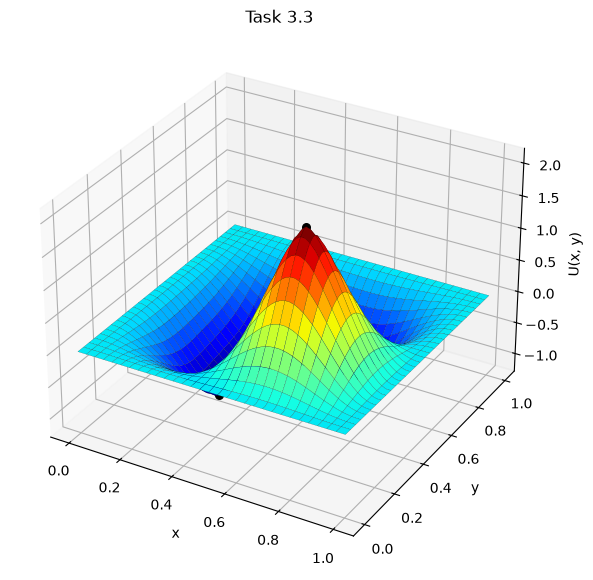

In [13]:
pts = [(1 / 3, 1 / 3, -1), (1 / 3, 2 / 3, -1), (2 / 3, 1 / 3, 2), (2 / 3, 2 / 3, -1)]
x, U = plate(lambda x, y: 0, n, points=pts)
surface(x, x, U, "Task 3.3", marks=pts)

#### Метод верхньої релаксації

iterations: 1346


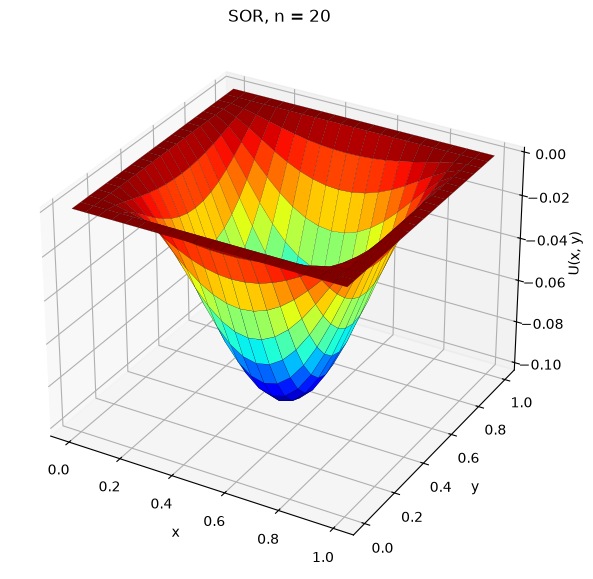

In [14]:
def relax(f, n, alpha=1.85, eps=1e-9):
    h = 1 / n
    x = np.linspace(0, 1, n + 1)
    U = np.zeros((n + 1, n + 1))
    F = np.array([[f(a, b) for b in x] for a in x]) * h**4
    it, err = 0, 1
    while err > eps:
        it += 1
        err = 0
        for i in range(2, n - 1):
            for j in range(2, n - 1):
                s = (U[i - 2, j] + U[i + 2, j] + U[i, j - 2] + U[i, j + 2]
                     - 8 * (U[i - 1, j] + U[i + 1, j] + U[i, j - 1] + U[i, j + 1])
                     + 2 * (U[i - 1, j - 1] + U[i - 1, j + 1] + U[i + 1, j - 1] + U[i + 1, j + 1]))
                new = U[i, j] + alpha * ((F[i, j] - s) / 20 - U[i, j])
                err = max(err, abs(new - U[i, j]))
                U[i, j] = new
    return x, U, it


x, Ur, it = relax(lambda x, y: -100, 20)
print("iterations:", it)
surface(x, x, Ur, "SOR, n = 20")

### 3. Полярні координати (осесиметричний випадок)

$$
\varphi^{IV} + \frac{2}{r}\varphi''' - \frac{1}{r^2}\varphi'' + \frac{1}{r^3}\varphi' = f(r), \quad r \in [1, 2]
$$

$$
\varphi''' \approx \frac{\varphi_{i+2} - 2\varphi_{i+1} + 2\varphi_{i-1} - \varphi_{i-2}}{2h^3}, \quad
\varphi'' \approx \frac{\varphi_{i+1} - 2\varphi_i + \varphi_{i-1}}{h^2}, \quad
\varphi' \approx \frac{\varphi_{i+1} - \varphi_{i-1}}{2h}
$$

$$
a_i = \frac{1}{h^4} - \frac{1}{r_ih^3}, \quad
b_i = -\frac{4}{h^4} + \frac{2}{r_ih^3} - \frac{1}{r_i^2h^2} - \frac{1}{2r_i^3h}, \quad
c_i = \frac{6}{h^4} + \frac{2}{r_i^2h^2},
$$

$$
d_i = -\frac{4}{h^4} - \frac{2}{r_ih^3} - \frac{1}{r_i^2h^2} + \frac{1}{2r_i^3h}, \quad
e_i = \frac{1}{h^4} + \frac{1}{r_ih^3}
$$

In [15]:
def polar(f, left, right, n=1000, ra=1, rb=2):
    h = (rb - ra) / n
    r = np.linspace(ra, rb, n + 1)
    ri = r[2:n - 1]
    A = np.zeros((5, n + 1))
    F = np.zeros(n + 1)
    A[0, 2:n - 1] = 1 / h**4 - 1 / (ri * h**3)
    A[1, 2:n - 1] = -4 / h**4 + 2 / (ri * h**3) - 1 / (ri**2 * h**2) - 1 / (2 * ri**3 * h)
    A[2, 2:n - 1] = 6 / h**4 + 2 / (ri**2 * h**2)
    A[3, 2:n - 1] = -4 / h**4 - 2 / (ri * h**3) - 1 / (ri**2 * h**2) + 1 / (2 * ri**3 * h)
    A[4, 2:n - 1] = 1 / h**4 + 1 / (ri * h**3)
    F[2:n - 1] = f(ri)
    set_bc(A, F, h, n, left, right)
    return r, progonka5(*A, F)


def show_polar(f, left, right, title):
    r, p = polar(f, left, right)
    th = np.linspace(0, 2 * np.pi, 120)
    R, TH = np.meshgrid(r[::10], th)
    fig = plt.figure(figsize=(13, 5))
    fig.suptitle(title)
    ax = fig.add_subplot(1, 2, 1)
    ax.plot(r, p)
    ax.set_xlabel("r")
    ax.set_ylabel("φ(r)")
    ax.grid()
    ax = fig.add_subplot(1, 2, 2, projection="3d")
    ax.plot_surface(R * np.cos(TH), R * np.sin(TH), np.tile(p[::10], (len(th), 1)), cmap="jet")
    plt.show()

#### Задача 4.4. Обидва краї кільця защемлені

$$
\varphi(1) = 1,\ \varphi'(1) = 0, \quad \varphi(2) = 0,\ \varphi'(2) = 0
$$

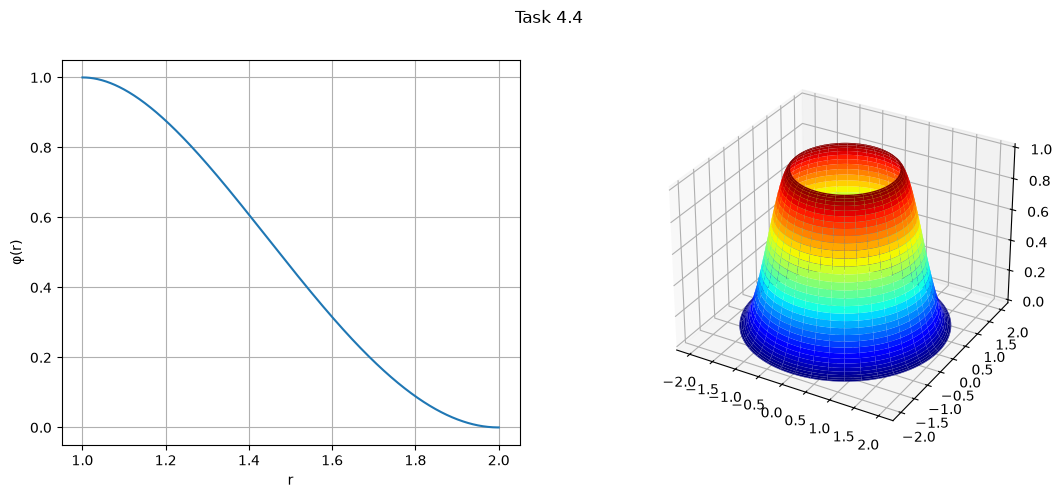

In [16]:
zero = lambda r: 0 * r
show_polar(zero, [(0, 1), (1, 0)], [(0, 0), (1, 0)], "Task 4.4")

#### Задача 4.5. Внутрішній край шарнірний

$$
\varphi(1) = 1,\ \varphi''(1) = 0, \quad \varphi(2) = 0,\ \varphi'(2) = 0
$$

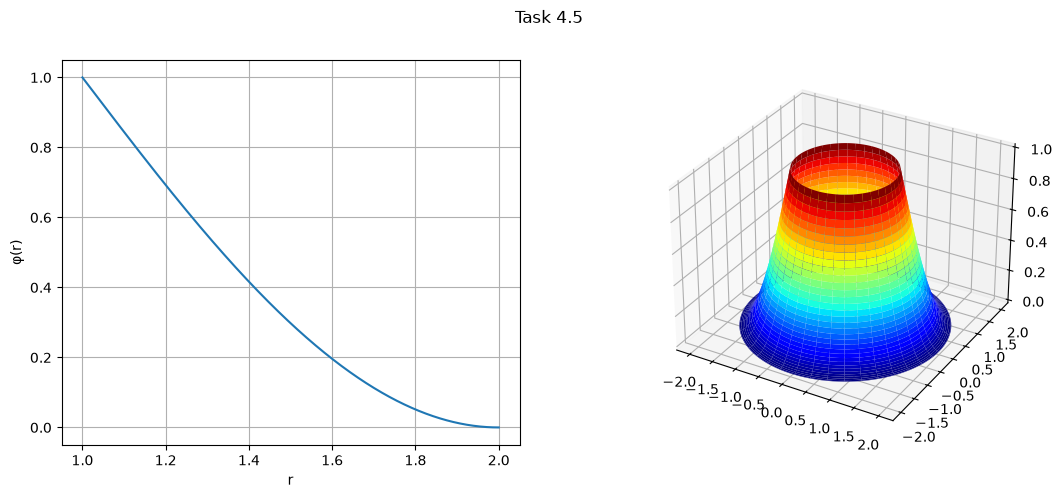

In [17]:
show_polar(zero, [(0, 1), (2, 0)], [(0, 0), (1, 0)], "Task 4.5")

#### Задача 4.6. Внутрішній край ковзає по вертикалі

$$
\varphi'(1) = \varphi''(1) = 0, \quad \varphi(2) = \varphi'(2) = 1
$$

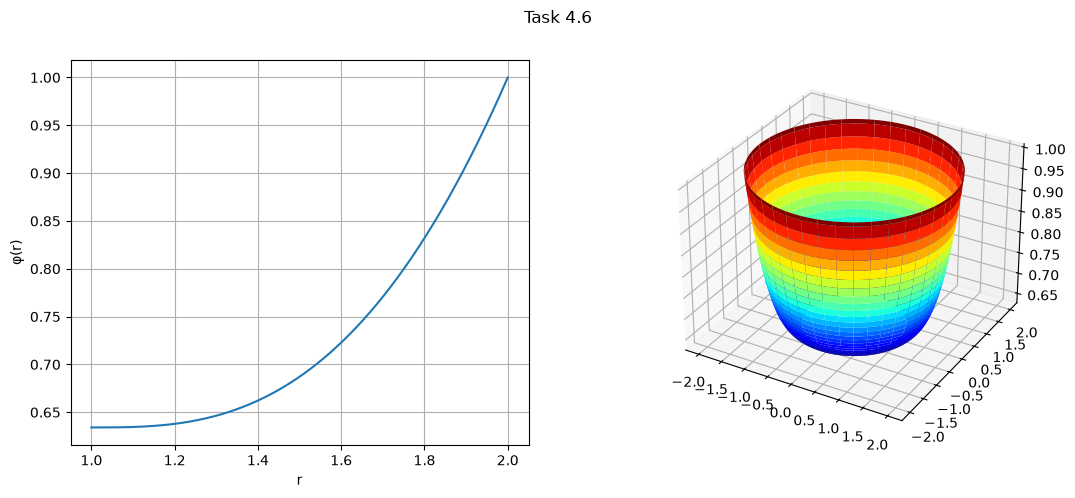

In [18]:
show_polar(zero, [(1, 0), (2, 0)], [(0, 1), (1, 1)], "Task 4.6")

### Висновки
1. П'ятидіагональна прогонка розв'язує одновимірні задачі за $O(n)$; для задач 2.3, 2.5, 2.8 чисельний розв'язок збігається з аналітичним.
2. Внутрішня опора — заміна рівняння у вузлі на $y_i = v$; у балці з'являється реакція (стрибок $y'''$).
3. У 2D 13-точкова схема зводиться до розрідженої СЛАР, яку можна розв'язати прямим методом або методом верхньої релаксації.
4. У полярних координатах схема залишається п'ятидіагональною, коефіцієнти залежать від $r_i$.